# Portfolio Analysis
## Objective
This notebook simulates a portfolio of identical term life insurance contracts and compares the mean present value of simulated claims against the theoretical expected value of the `TermLifeInsurance` class. The notebook also contains a monte carlo simulation of 1000 portfolios and visualizes the sample distribution of the present value of the total portfolio claims. All results are reported separately for male and female policyholders.

**Agenda**:
1. Simulate 100,000 identical contracts with `sample_death_ages()`
2. Compare the mean present value of simulated claims with its theoretical expected value
3. Run 1,000 Monte Carlo simulations to study the distribution of portfolio claims

**Assumptions** (same as in `TermLifeInsurance`): the death benefit is paid at the end of the year of death, and only deaths within the term cause a claim.

**Note**: the mortality data ends with age 100 which means that deaths with age 100 are not actually deaths but individuals that survived the age 100.

In [1]:
# Import libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mortality import MortalityTable
from products import TermLifeInsurance

In [2]:
# Load mortality data
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (PROJECT_ROOT / "data" / "processed" / "mortality_table.csv")

df = pd.read_csv(DATA_PATH)

mortality_table = MortalityTable(df)

In [3]:
# Contract parameters
TERM = 20
INTEREST_RATE = 0.03
DEATH_BENEFIT = 100000
AGE_INDIVIDUAL = 40

# Simulation parameters
N_CONTRACTS = 100000
N_SIMULATIONS = 1000
SEED = 40

# Create insurance contract
insurance = TermLifeInsurance(term=TERM, interest_rate=INTEREST_RATE, death_benefit=DEATH_BENEFIT, mortality_table=mortality_table)

## Theoretical benchmarks

For a single contract, let $K$ be the year of death and $X = C\,v^{K}\,\mathbf{1}\{K \le n\}$ the PV of the claim. Then (as more detailed described in notebook 02):

$$E[X] = C \sum_{k=1}^{n} v^k {}_{k-1|}q_x$$

The sample mean is cross-checked against `TermLifeInsurance.expected_present_value_benefit()` which implements this theoretical EPV of the benefits with given model assumptions also described in notebook 02.

## 1. Simulate 100,000 identical contracts
(100,000 contracts for male and 100,000 contracts for female individuals)

In [4]:
# Create 100000 death age samples for male and female individuals with given starting age
death_ages = []

death_ages_male = mortality_table.sample_death_ages(
    age=AGE_INDIVIDUAL, gender= 'male', n_samples=N_CONTRACTS, seed=SEED
)

death_ages_female = mortality_table.sample_death_ages(
    age=AGE_INDIVIDUAL, gender= 'female', n_samples=N_CONTRACTS, seed=SEED
)

for male, female in zip(death_ages_male, death_ages_female):
    death_ages.append({'death_age': male, 'gender': 'male'})
    death_ages.append({'death_age': female, 'gender': 'female'})

death_ages_data = pd.DataFrame(death_ages)
death_ages_data.head()

,death_age,gender
0,88,male
1,91,female
2,87,male
3,90,female
4,94,male


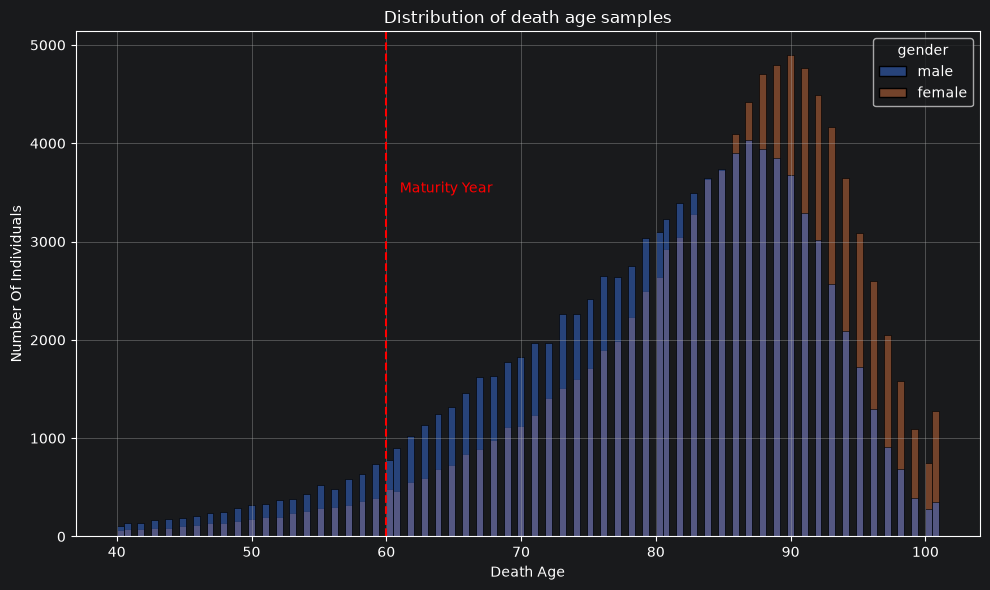

        death_within_contract  death_after_contract
gender                                             
male                     6708                 93292
female                   3768                 96232


In [5]:
# Visualize death ages distribution

plt.figure(figsize=(10, 6))

sns.histplot(data=death_ages_data, x='death_age', hue='gender')

# plot vertical line at maturity year of the contracts
maturity_year = AGE_INDIVIDUAL + TERM
plt.axvline(x=maturity_year, color='r', linestyle='--')
plt.text(x=maturity_year + 1, y= 3500, s='Maturity Year', color='r')

plt.title("Distribution of death age samples")

plt.xlabel("Death Age")
plt.ylabel("Number Of Individuals")

plt.grid(True)
plt.tight_layout()

# safe figure
FIGURE_PATH = (PROJECT_ROOT / "reports" / "figures" / "distribution_of_death_age_samples.png")
plt.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")

plt.show()

# Print the data
death_ages_summary = (death_ages_data.assign(
    death_within_contract = death_ages_data.death_age < maturity_year,
    death_after_contract = death_ages_data.death_age >= maturity_year,
)
.groupby('gender')[['death_within_contract', 'death_after_contract']].sum()
.reindex(['male', 'female'])
)
print(death_ages_summary)

## 2. Compare the mean present value of simulated claims with its theoretical expected value

In [6]:
# Create a flag if there is a claim for the individual
death_ages_data['claim'] = death_ages_data['death_age'] < maturity_year

# Create column with discount years (e.g. if individual has death age 40, then the claim has to be discounted one year sice the claim is paid at the end of the year.)
death_ages_data['discount_years'] = death_ages_data['death_age'] - (AGE_INDIVIDUAL-1)
v = insurance.discount_factor

# Create method to calculate present_value of the claim
def present_value_of_claim(claim: int, discount_factor: float, discount_years: int):
    return claim * (discount_factor ** discount_years)

# Add column with the present value of the claim for each individual
# (note that this is calculated even if no claim exists)
death_ages_data['pv_claim'] = [
    present_value_of_claim(DEATH_BENEFIT, v, disc_years)
    for disc_years in death_ages_data['discount_years']
]

# set the present value of claims to 0 if no claim exists
death_ages_data['pv_claim'] = death_ages_data['pv_claim'].where(death_ages_data['claim'], 0)


# Get the mean of the simulated present value of claims
mean_pv_claims_male = death_ages_data.loc[death_ages_data.gender == 'male']['pv_claim'].mean()
mean_pv_claims_female = death_ages_data.loc[death_ages_data.gender == 'female']['pv_claim'].mean()

# Get the theoretical expected values
theory_epv_male = insurance.expected_present_value_benefit(age=AGE_INDIVIDUAL, gender='male')
theory_epv_female = insurance.expected_present_value_benefit(age=AGE_INDIVIDUAL, gender='female')

print(f"Mean PV of simulated claims male: {round(mean_pv_claims_male, 2)}")
print(f"Theoretical epv male: {round(theory_epv_male, 2)}")
print(f"Mean PV of simulated claims female: {round(mean_pv_claims_female, 2)}")
print(f"Theoretical epv female: {round(theory_epv_female, 2)}")


Mean PV of simulated claims male: 4567.43
Theoretical epv male: 4666.49
Mean PV of simulated claims female: 2562.46
Theoretical epv female: 2607.19


## 3. Run 1,000 Monte Carlo Simulations to study the distribution of portfolio claims

In [7]:
# Simulation results
pv_of_portfolio_claims_male = []
pv_of_portfolio_claims_female = []

# Monte Carlo Simulation
for n in range(N_SIMULATIONS):

    # Create 100000 death age samples for male and female individuals with given starting age
    death_ages = []

    # Sample death ages and use n as seed for the random sample
    death_ages_male = mortality_table.sample_death_ages(
        age=AGE_INDIVIDUAL, gender= 'male', n_samples=N_CONTRACTS, seed=n
    )

    death_ages_female = mortality_table.sample_death_ages(
        age=AGE_INDIVIDUAL, gender= 'female', n_samples=N_CONTRACTS, seed=n
    )

    for male, female in zip(death_ages_male, death_ages_female):
        death_ages.append({'death_age': male, 'gender': 'male'})
        death_ages.append({'death_age': female, 'gender': 'female'})

    death_ages_data = pd.DataFrame(death_ages)

    # Create a flag if there is a claim for the individual
    death_ages_data['claim'] = death_ages_data['death_age'] < maturity_year

    # Create column with discount years (e.g. if individual has death age 40, then the claim has to be discounted one year sice the claim is paid at the end of the year.)
    death_ages_data['discount_years'] = death_ages_data['death_age'] - (AGE_INDIVIDUAL-1)

    # Add column with the present value of the claim for each individual
    # (note that this is calculated even if no claim exists)
    death_ages_data['pv_claim'] = [
        present_value_of_claim(DEATH_BENEFIT, v, disc_years)
        for disc_years in death_ages_data['discount_years']
    ]

    # set the present value of claims to 0 if no claim exists
    death_ages_data['pv_claim'] = death_ages_data['pv_claim'].where(death_ages_data['claim'], 0)

    # Calculate the sum of claims
    pv_of_total_portfolio_claims_male = death_ages_data.loc[
        death_ages_data.gender == 'male']['pv_claim'].sum()
    pv_of_total_portfolio_claims_female = death_ages_data.loc[
        death_ages_data.gender == 'female']['pv_claim'].sum()

    pv_of_portfolio_claims_male.append(pv_of_total_portfolio_claims_male)
    pv_of_portfolio_claims_female.append(pv_of_total_portfolio_claims_female)


         sample_mean    sample_std
male    4.664933e+08  5.550712e+06
female  2.606207e+08  4.271090e+06


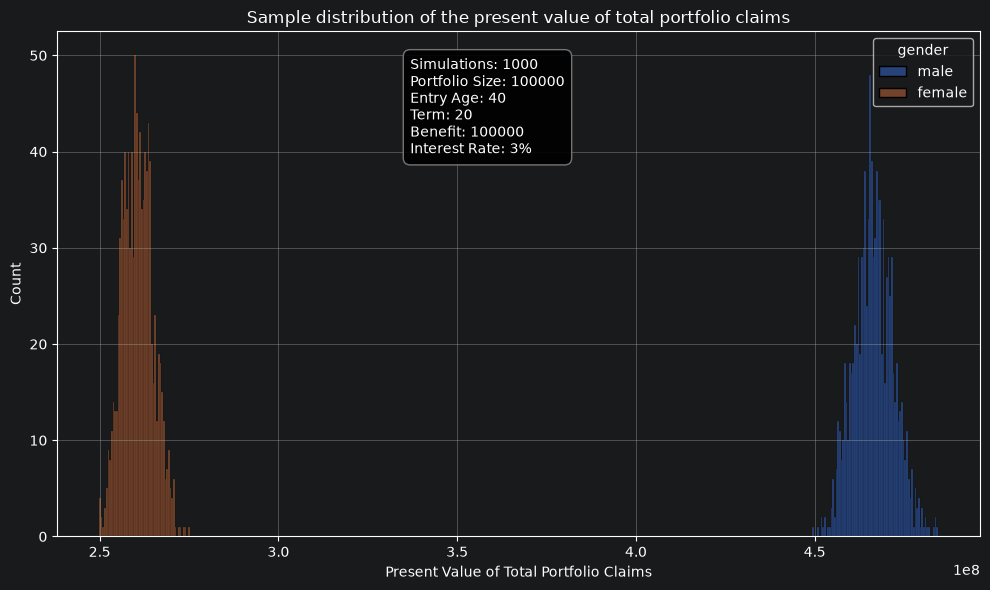

In [8]:
# Visualize Results

# Create a DataFrame for plotting
data = pd.DataFrame(
    {"portfolio_claims": pv_of_portfolio_claims_male + pv_of_portfolio_claims_female,
     "gender": ['male'] * len(pv_of_portfolio_claims_male) + ['female'] * len(pv_of_portfolio_claims_female)}
)

plt.figure(figsize=(10, 6))

ax = sns.histplot(data=data, x="portfolio_claims", hue="gender", bins=500)

# Plot box with model parameters
params_text = (
    "Simulations: 1000\n"
    "Portfolio Size: 100000\n"
    "Entry Age: 40\n"
    "Term: 20\n"
    "Benefit: 100000\n"
    "Interest Rate: 3%"
)

ax.text(
    0.55, 0.95,               # x, y position in axes fraction (0 to 1)
    params_text,
    transform=ax.transAxes,   # use axes coordinates (0,0 = bottom-left, 1,1 = top-right)
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    multialignment="left",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="black",
        edgecolor="gray",
        alpha=0.9,
    ),
)

plt.title("Sample distribution of the present value of total portfolio claims")

plt.xlabel("Present Value of Total Portfolio Claims")
plt.ylabel("Count")

plt.grid(True)

plt.tight_layout()

# save figure
FIGURE_PATH = (PROJECT_ROOT / "reports" / "figures" / "distribution_total_portfolio_claims.png")
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")

# Print the data
simulation_summary = pd.DataFrame(
    {
        'sample_mean': {
            'male': np.mean(pv_of_portfolio_claims_male),
            'female': np.mean(pv_of_portfolio_claims_female)
        },
        'sample_std': {
            'male': np.std(pv_of_portfolio_claims_male),
            'female': np.std(pv_of_portfolio_claims_female)
        }
    }
)
print(simulation_summary)